# 04 · Evaluation on held-out noise
Test grid: **test-clean + test-other** (5,559 utterances, 10.7 h, unseen speakers) × **17 conditions**:
- clean;
- **held-out noise:** brown and ESC-50 at 20/10/5/0 dB;
- **seen noise types** (the white and pink generators were used in training, but these test samples are fresh draws): white and pink at 20/10/5/0 dB.

That is 94,503 decoded utterances per model. Decoding is greedy CTC with no language model. Code: `scripts/evaluate.py`.

| Model | Description |
|---|---|
| `ref_base960h` | public `facebook/wav2vec2-base-960h` (fine-tuned on all 960 h of clean LibriSpeech), as a reference point |
| `A_clean` | ours: wav2vec2-base + CTC on clean train-clean-100 |
| `B_noisy` | ours: same recipe + noise augmentation |

**O2 target:** B reduces WER by at least 15% relative to A, averaged over 0 and 5 dB, while clean WER worsens by no more than 2 points.

In [1]:
import sys, json, warnings
from pathlib import Path
cwd = Path.cwd()
REPO = next(p for p in (cwd, *cwd.parents) if (p / "src" / "group9_ds_ai_lab").is_dir())
sys.path.insert(0, str(REPO / "src"))
from group9_ds_ai_lab.utils.paths import *   # noqa  (all project paths)
setup_env()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown, Audio
from group9_ds_ai_lab.utils.plotstyle import apply_style, SERIES, INK, INK2, GRID, SURF, MODEL_COLOR, MODEL_LABEL, NOISE_COLOR
apply_style(); warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)
print("repo:", REPO)

repo: <repo root>


In [2]:
MODELS = [m for m in ("ref_base960h", "A_clean", "B_noisy") if (EVAL / m / "summary.csv").exists()]
print("evaluated models:", MODELS)
summ = pd.concat([pd.read_csv(EVAL / m / "summary.csv") for m in MODELS])
summ["snr_db"] = summ.snr_db.astype(str)
SNR_ORDER = ["clean", "20", "10", "5", "0"]
grid = summ.pivot_table(index=["model", "ls_split", "noise_type"], columns="snr_db", values="wer")
display((grid[[c for c in SNR_ORDER if c in grid.columns]] * 100).round(2))

evaluated models: ['ref_base960h', 'A_clean', 'B_noisy']


snr_db                              clean     20     10      5      0
model        ls_split   noise_type                                   
A_clean      test.clean brown         NaN  5.880  5.940  6.060  6.260
                        clean       5.850    NaN    NaN    NaN    NaN
                        esc50         NaN  6.810 12.060 20.550 38.300
                        pink          NaN  6.370 10.410 25.600 66.340
                        white         NaN  7.260 18.150 44.040 82.560
             test.other brown         NaN 13.060 13.430 13.970 14.770
                        clean      13.030    NaN    NaN    NaN    NaN
                        esc50         NaN 16.100 27.250 39.440 54.960
                        pink          NaN 15.980 28.760 50.850 81.480
                        white         NaN 20.160 43.540 68.400 91.190
B_noisy      test.clean brown         NaN  6.240  6.220  6.300  6.370
                        clean       6.190    NaN    NaN    NaN    NaN
                        esc50         NaN  6.430  7.690  9.540 15.670
                        pink          NaN  6.370  7.490 10.040 18.060
                        white         NaN  6.680  8.740 13.020 23.450
             test.other brown         NaN 13.130 13.230 13.430 14.020
                        clean      13.080    NaN    NaN    NaN    NaN
                        esc50         NaN 14.170 17.980 23.010 32.330
                        pink          NaN 14.040 18.350 25.090 39.700
                        white         NaN 15.330 22.600 31.510 48.480
ref_base960h test.clean brown         NaN  3.400  3.430  3.520  3.660
                        clean       3.430    NaN    NaN    NaN    NaN
                        esc50         NaN  3.990  8.850 18.210 35.730
                        pink          NaN  3.850  9.550 35.890 78.750
                        white         NaN  4.690 22.250 59.630 91.190
             test.other brown         NaN  8.630  8.840  9.230  9.800
                        clean       8.590    NaN    NaN    NaN    NaN
                        esc50         NaN 11.140 21.590 34.710 50.120
                        pink          NaN 11.040 28.050 58.490 89.130
                        white         NaN 14.910 45.960 76.760 95.200

## WER vs SNR: one panel per noise type

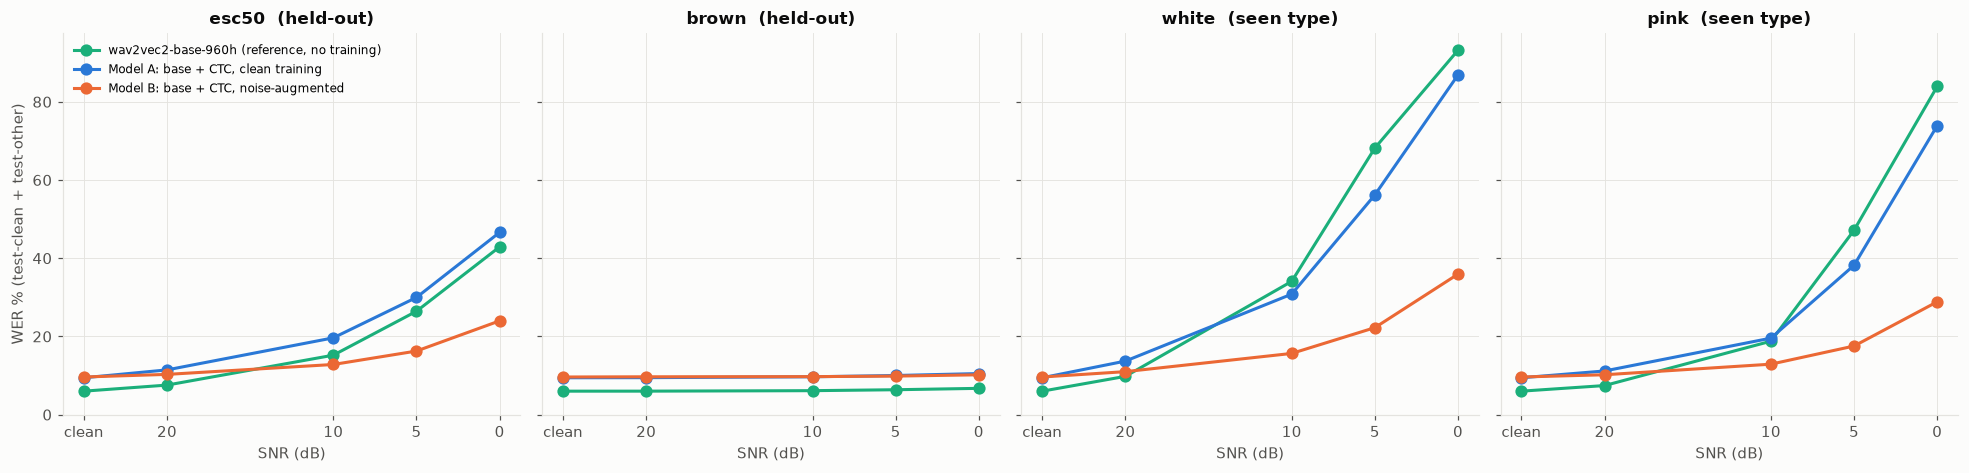

In [3]:
import jiwer
def pooled(m):  # pool test-clean + test-other per condition (word-weighted)
    p = pd.read_parquet(EVAL / m / "predictions.parquet"); p["snr"] = p.snr_db.fillna(-1).astype(int).astype(str).replace("-1", "clean")
    return pd.DataFrame([{"model": m, "noise_type": n, "snr": s, "wer": jiwer.wer(g.text.tolist(), g.hyp.tolist()),
                          "cer": jiwer.cer(g.text.tolist(), g.hyp.tolist())} for (n, s), g in p.groupby(["noise_type", "snr"])])
P = pd.concat([pooled(m) for m in MODELS])
NOISES = ["esc50", "brown", "white", "pink"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4), sharey=True)
x = {"clean": 25, "20": 20, "10": 10, "5": 5, "0": 0}
for ax, nt in zip(axes, NOISES):
    for m in MODELS:
        d = pd.concat([P[(P.model == m) & (P.noise_type == "clean")], P[(P.model == m) & (P.noise_type == nt)]])
        d = d.assign(xx=d.snr.map(x)).sort_values("xx")
        ax.plot(d.xx, d.wer * 100, marker="o", color=MODEL_COLOR[m], label=MODEL_LABEL[m])
    ax.set_xticks([0, 5, 10, 20, 25], ["0", "5", "10", "20", "clean"]); ax.invert_xaxis()
    ax.set(title=nt + ("  (held-out)" if nt in ("esc50", "brown") else "  (seen type)"), xlabel="SNR (dB)")
axes[0].set_ylim(bottom=0); axes[0].set_ylabel("WER % (test-clean + test-other)"); axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

## O2: does noise-aware training help?

In [4]:
def o2(P, a="A_clean", b="B_noisy"):
    rows = []
    for nt in NOISES:
        wa = P[(P.model == a) & (P.noise_type == nt) & P.snr.isin(["0", "5"])].wer.mean()
        wb = P[(P.model == b) & (P.noise_type == nt) & P.snr.isin(["0", "5"])].wer.mean()
        rows.append({"noise": nt, f"{a} WER@0/5dB": wa*100, f"{b} WER@0/5dB": wb*100, "relative reduction %": 100*(wa-wb)/wa})
    ca = P[(P.model == a) & (P.noise_type == "clean")].wer.iloc[0] * 100; cb = P[(P.model == b) & (P.noise_type == "clean")].wer.iloc[0] * 100
    t = pd.DataFrame(rows)
    display(t)
    held = t[t.noise.isin(["esc50", "brown"])]["relative reduction %"].mean()
    display(Markdown(f"- Clean WER: **{a} {ca:.2f}% → {b} {cb:.2f}%** (change {cb-ca:+.2f} points; target ≤ +2) "
                     f"→ {'✅' if cb-ca <= 2 else '❌'}\n- Mean relative WER reduction at 0/5 dB on **held-out** noise: **{held:.1f}%** "
                     f"(target ≥ 15%) → {'✅' if held >= 15 else '❌'}\n- On all four noise types: **{t['relative reduction %'].mean():.1f}%**"))
if {"A_clean", "B_noisy"} <= set(MODELS): o2(P)
else: print("O2 needs both A_clean and B_noisy - re-run once both evaluations exist.")

,noise,A_clean WER@0/5dB,B_noisy WER@0/5dB,relative reduction %
0,esc50,38.292,20.124,47.447
1,brown,10.257,10.022,2.295
2,white,71.533,29.091,59.331
3,pink,56.047,23.202,58.602


- Clean WER: **A_clean 9.43% → B_noisy 9.62%** (change +0.20 points; target ≤ +2) → ✅
- Mean relative WER reduction at 0/5 dB on **held-out** noise: **24.9%** (target ≥ 15%) → ✅
- On all four noise types: **41.9%**

## Example transcripts across noise levels (held-out ESC-50)

In [5]:
preds = {m: pd.read_parquet(EVAL / m / "predictions.parquet") for m in MODELS}
uid = preds[MODELS[0]].query("noise_type == 'clean' and ls_split == 'test.clean' and duration < 6").audio_id.iloc[5]
rows = []
for nt, s in [("clean", None), ("esc50", 20), ("esc50", 10), ("esc50", 5), ("esc50", 0)]:
    r = {"condition": nt if s is None else f"{nt} {s} dB"}
    for m in MODELS:
        p = preds[m]; q = p[(p.audio_id == uid) & (p.noise_type == nt) & ((p.snr_db == s) if s is not None else p.snr_db.isna())]
        r[m] = q.hyp.iloc[0]
    rows.append(r)
print("REFERENCE:", preds[MODELS[0]].query("audio_id == @uid").text.iloc[0])
with pd.option_context("display.max_colwidth", 90): display(pd.DataFrame(rows))

REFERENCE: I CAN PERCEIVE LOVE CLEARLY ENOUGH


,condition,ref_base960h,A_clean,B_noisy
0,clean,I CAN PERCEIVE LOVE CLEARLY ENOUGH,I CAN PERCEIVE LOVE CLEARLY ENOUGH,I CAN PERCEIVE LOVE CLEARLY ENOUGH
1,esc50 20 dB,I CAN PERCEIVE LOVE CLEARLY ENOUGH,I CAN PERCEIVE LOVE CLEARLY ENOUGH,I CAN PERCEIVE LOVE CLEARLY ENOUGH
2,esc50 10 dB,I CAN PERCEIVE LOVE CLEARLY ENOUGH,I CAN PERCEIVE LOVE CLEARLY ENOUGH,I CAN PERCEIVE LOVE CLEARLY ENOUGH
3,esc50 5 dB,I CAN PERCEIVE LOVE CLEARLY ENOUGH,I CAN PERCEIVE LOVE CLEARLY ENOUGH,I CAN PERCEIVE LOVE CLEARLY ENOUGH
4,esc50 0 dB,I CAN PERCEIVE LOVE CLEARLY ENOUGH,I CAN PERSEIVE BOB BY THEOBEAMAT,I CAN PERCEIVE LOVE CLEARLY ENOUGH


## Preview for Milestone 5: word-level error detection (O3)
Each hypothesis word gets a confidence: the minimum, over the frames that emit it, of the CTC max-posterior. It is labelled wrong if it is part of a substitution or an insertion against the reference. Targets: **AUROC ≥ 0.75**, and **≥ 70% of errors fall within the riskiest 30% of words**.

In [6]:
from sklearn.metrics import roc_auc_score
rows = []
for m in MODELS:
    w = pd.read_parquet(EVAL / m / "words.parquet")
    for nt, g in [("all", w)] + list(w.groupby("noise_type")):
        risk = 1 - g.conf_min; k = int(.3 * len(g))
        top = g.is_error.values[np.argsort(-risk.values)[:k]].sum() / max(g.is_error.sum(), 1)
        rows.append({"model": m, "noise": nt, "words": len(g), "error_rate %": g.is_error.mean()*100,
                     "AUROC": roc_auc_score(g.is_error, risk) if g.is_error.nunique() == 2 else np.nan,
                     "errors caught in riskiest 30% (%)": top*100})
display(pd.DataFrame(rows).round(3))

,model,noise,words,error_rate %,AUROC,errors caught in riskiest 30% (%)
0,ref_base960h,all,1649118,21.528,0.904,79.207
1,ref_base960h,brown,419597,5.784,0.790,70.095
2,ref_base960h,clean,104914,5.515,0.785,68.752
3,ref_base960h,esc50,400959,18.245,0.884,77.651
4,ref_base960h,pink,363549,28.631,0.907,74.996
5,ref_base960h,white,360099,41.021,0.920,67.374
6,A_clean,all,1714306,24.294,0.862,70.725
7,A_clean,brown,419027,9.095,0.775,66.433
8,A_clean,clean,104823,8.684,0.770,65.912
9,A_clean,esc50,410484,23.317,0.850,69.113


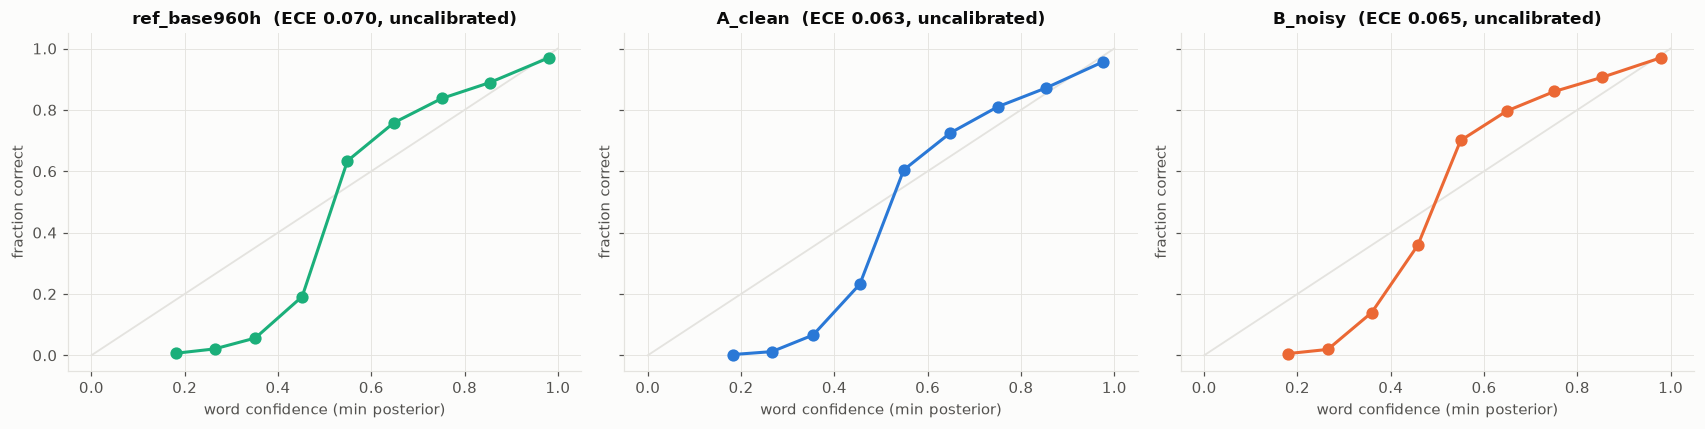

In [7]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(5.2*len(MODELS), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, m in zip(axes, MODELS):
    w = pd.read_parquet(EVAL / m / "words.parquet")
    bins = np.linspace(0, 1, 11); b = np.clip(np.digitize(w.conf_min, bins) - 1, 0, 9)
    acc = w.groupby(b).is_error.apply(lambda s: 1 - s.mean()); cnt = w.groupby(b).size()
    ece = (cnt / cnt.sum() * (acc - w.groupby(b).conf_min.mean()).abs()).sum()
    ax.plot([0, 1], [0, 1], color=GRID, lw=1.2); ax.plot(w.groupby(b).conf_min.mean(), acc, marker="o", color=MODEL_COLOR[m])
    ax.set(title=f"{m}  (ECE {ece:.3f}, uncalibrated)", xlabel="word confidence (min posterior)", ylabel="fraction correct")
plt.tight_layout(); plt.show()